# Construção da Tabela Mestra Consolidada (Feature Store) - Base Bruta

## 1. Contexto e Objetivo do Pipeline de Engenharia de Recursos

Este notebook realiza a integração e consolidação das **4 fontes de dados tratadas** do sistema de Portas de Plataforma (PSDs) da Linha 4-Amarela em uma única **Tabela Mestra (*Feature Matrix / Feature Store*)**:

1. **`Alarmes PSD Limpos`**: Histórico desduplicado e sanitizado de eventos e tempos de normalização (> 30s).
2. **`Corretivas Emergenciais (ZM01)`**: Ordens de manutenção de quebra funcional emergencial (base do **Target**).
3. **`Corretivas Programadas (ZM02)`**: Ordens de manutenção corretiva programada/agendada.
4. **`Preventivas (ZM03)`**: Ordens de manutenção preventiva periódica (lubrificação, revisão e ajustes de guias).

### Metodologia de Modelagem Temporal:
* **Granularidade:** Diária (1 linha para cada Porta em cada Dia Operacional entre 2023 e 2026).
* **Janelas de Observação (*Lags* - Olhar para Trás):** Métricas de estresse acumulado em 1d, 7d e 14d, além do tempo decorrido desde as últimas manutenções (ZM01, ZM02, ZM03).
* **Janela Preditiva (*Lead* - Olhar para Frente / Target):** Identificador binário **`target_falha_7d`** (1 se a porta abrir uma ordem corretiva emergencial ZM01 nos próximos 7 dias $[D+1, D+7]$, e 0 caso contrário).
* **Preservação do Estado Bruto:** Esta etapa **não aplica encodings ou normalizações antecipadas**, mantendo as variáveis em formato natural e interpretável para auditoria.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import warnings
from datetime import timedelta

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print("✅ Bibliotecas importadas com sucesso!")


✅ Bibliotecas importadas com sucesso!


## 2. Carregamento e Padronização das Chaves Primárias

Para cruzar as 4 bases com precisão, decompomos as TAGs e os Locais de Instalação do SAP em uma chave padronizada composta por:
* `estacao`: Sigla oficial da estação (`BUT`, `PIN`, `REP`, `LUZ`, `FRA`, `HIG`, `PTA`, `FRE`, `MBI`, `VSO`, `FAL`).
* `plataforma`: Via operacional (`P1`, `P2`).
* `porta`: Número ordinal da porta (`1` a `24`).
* `id_ativo`: Identificador unificado (ex: `BUT_P1_PDM12`).


In [2]:
# 1. Carregamento da Base de Alarmes Limpa (com Recuperação de Morumbi - MBI)
print("Carregando base de alarmes limpa...")
path_alarmes = "../../data/Alarmes/alarmes_trata_limpos_consolidado.csv"
df_alarmes = pd.read_csv(path_alarmes, low_memory=False)

# Unificar colunas maiusculas e minusculas para recuperar estacao Morumbi (MBI)
df_alarmes['estacao'] = df_alarmes['estacao'].fillna(df_alarmes['Estação'])
df_alarmes['porta'] = df_alarmes['porta'].fillna(df_alarmes['Porta'])

def extrair_plt(tag):
    m = re.search(r'_([A-Z]{3})(\d)_', str(tag))
    if m:
        return f'P{m.group(2)}'
    return 'P1'

df_alarmes['plataforma'] = df_alarmes['plataforma'].fillna(df_alarmes['TAG'].apply(extrair_plt))
df_alarmes['data_evento'] = pd.to_datetime(df_alarmes['Horário do Alarme'], errors='coerce').dt.normalize()
df_alarmes = df_alarmes.dropna(subset=['estacao', 'plataforma', 'porta', 'data_evento']).copy()
df_alarmes['porta'] = df_alarmes['porta'].astype(int)
df_alarmes['id_ativo'] = df_alarmes['estacao'] + "_" + df_alarmes['plataforma'] + "_PDM" + df_alarmes['porta'].apply(lambda x: f"{x:02d}")
df_alarmes['tempo_normalizacao_seg'] = pd.to_numeric(df_alarmes['tempo_normalizacao_seg'], errors='coerce').fillna(0)
df_alarmes['is_anomalia_30s'] = (df_alarmes['tempo_normalizacao_seg'] >= 30).astype(int)
print(f"✅ Alarmes carregados e consolidados: {len(df_alarmes):,} registros.")
print(f"   -> Estações mapeadas ({df_alarmes['estacao'].nunique()}): {sorted(df_alarmes['estacao'].unique())}")


Carregando base de alarmes limpa...
Alarmes carregados: 656,603 registros válidos.
Carregando ZM01...
ZM01 carregadas com porta identificada: 9,357 registros.
Carregando ZM02...
ZM02 carregadas com porta identificada: 1,010 registros.
Carregando ZM03...
ZM03 carregadas: 569 registros.


## 3. Construção da Grade Temporal Base Contínua (Ativo $	imes$ Dia)

Para garantir que o modelo aprenda tanto os dias normais de operação quanto os dias que antecedem uma quebra, criamos uma matriz diária contínua para todas as portas ativas identificadas.


In [3]:
# Mapeamento de ativos únicos monitorados
ativos_unicos = df_alarmes[['id_ativo', 'estacao', 'plataforma', 'porta']].drop_duplicates().sort_values('id_ativo').reset_index(drop=True)
print(f"Total de ativos únicos monitorados (Portas de Plataforma): {len(ativos_unicos):,}")

# Intervalo temporal completo da análise (2023 a 2026)
data_min = pd.to_datetime('2023-01-01')
data_max = pd.to_datetime('2026-02-28')
datas_todas = pd.date_range(start=data_min, end=data_max, freq='D')
print(f"Total de dias operacionais no período: {len(datas_todas):,} dias.")

# Construção do Produto Cartesiano (Ativo x Data)
grade_base = []
for _, row in ativos_unicos.iterrows():
    df_temp = pd.DataFrame({'data_ref': datas_todas})
    df_temp['id_ativo'] = row['id_ativo']
    df_temp['estacao'] = row['estacao']
    df_temp['plataforma'] = row['plataforma']
    df_temp['porta'] = row['porta']
    grade_base.append(df_temp)

df_mestra = pd.concat(grade_base, ignore_index=True)
df_mestra = df_mestra.sort_values(['id_ativo', 'data_ref']).reset_index(drop=True)
print(f"Matriz diária contínua gerada: {len(df_mestra):,} linhas.")
display(df_mestra.head())



Total de ativos únicos monitorados (Portas de Plataforma): 478
Total de dias operacionais no período: 1,155 dias.
Matriz diária contínua gerada: 552,090 linhas.


,data_ref,id_ativo,estacao,plataforma,porta
0,2023-01-01,BUT_P1_PDM01,BUT,P1,1
1,2023-01-02,BUT_P1_PDM01,BUT,P1,1
2,2023-01-03,BUT_P1_PDM01,BUT,P1,1
3,2023-01-04,BUT_P1_PDM01,BUT,P1,1
4,2023-01-05,BUT_P1_PDM01,BUT,P1,1


## 4. Agregação Diária de Alarmes e Cálculo de Janelas Móveis (*Lags*)

Para cada dia $D$ da porta, agregamos os alarmes ocorridos e calculamos métricas em janelas passadas de **1 dia, 7 dias e 14 dias** (*lags*), evitando estritamente vazamento de dados futuros.


In [4]:
# Agregação diária por ativo
df_alarmes_agg = df_alarmes.groupby(['id_ativo', 'data_evento']).agg(
    qtd_alarmes_dia=('TAG', 'count'),
    qtd_anomalias_30s_dia=('tempo_normalizacao_seg', lambda x: (x > 30).sum()),
    tempo_parada_total_seg_dia=('tempo_normalizacao_seg', 'sum'),
    max_tempo_normalizacao_dia=('tempo_normalizacao_seg', 'max'),
    qtd_alarmes_rce_dia=('tipo_alarme', lambda x: (x == 'RCE').sum()),
    qtd_alarmes_fo_dia=('tipo_alarme', lambda x: (x == 'FO').sum()),
    qtd_alarmes_lsd_dia=('tipo_alarme', lambda x: (x == 'LSD').sum())
).reset_index()

df_alarmes_agg.rename(columns={'data_evento': 'data_ref'}, inplace=True)

# Merge com a grade contínua
df_mestra = pd.merge(df_mestra, df_alarmes_agg, on=['id_ativo', 'data_ref'], how='left')

# Preenchimento de dias sem alarmes com zero
cols_alarmes = ['qtd_alarmes_dia', 'qtd_anomalias_30s_dia', 'tempo_parada_total_seg_dia', 
                'max_tempo_normalizacao_dia', 'qtd_alarmes_rce_dia', 'qtd_alarmes_fo_dia', 'qtd_alarmes_lsd_dia']
df_mestra[cols_alarmes] = df_mestra[cols_alarmes].fillna(0)

# Cálculo das Janelas Móveis Passadas (Lags: shift 1 para olhar estritamente o passado)
print("Calculando janelas móveis temporais (Lags)...")
grouped = df_mestra.groupby('id_ativo')

df_mestra['qtd_alarmes_1d'] = grouped['qtd_alarmes_dia'].shift(1).fillna(0)
df_mestra['qtd_alarmes_7d'] = grouped['qtd_alarmes_dia'].shift(1).rolling(7, min_periods=1).sum().fillna(0)
df_mestra['qtd_alarmes_14d'] = grouped['qtd_alarmes_dia'].shift(1).rolling(14, min_periods=1).sum().fillna(0)

df_mestra['qtd_anomalias_30s_1d'] = grouped['qtd_anomalias_30s_dia'].shift(1).fillna(0)
df_mestra['qtd_anomalias_30s_7d'] = grouped['qtd_anomalias_30s_dia'].shift(1).rolling(7, min_periods=1).sum().fillna(0)
df_mestra['qtd_anomalias_30s_14d'] = grouped['qtd_anomalias_30s_dia'].shift(1).rolling(14, min_periods=1).sum().fillna(0)

df_mestra['tempo_parada_acumulado_7d'] = grouped['tempo_parada_total_seg_dia'].shift(1).rolling(7, min_periods=1).sum().fillna(0)
df_mestra['max_tempo_normalizacao_7d'] = grouped['max_tempo_normalizacao_dia'].shift(1).rolling(7, min_periods=1).max().fillna(0)

df_mestra['qtd_alarmes_rce_7d'] = grouped['qtd_alarmes_rce_dia'].shift(1).rolling(7, min_periods=1).sum().fillna(0)
df_mestra['qtd_alarmes_fo_7d'] = grouped['qtd_alarmes_fo_dia'].shift(1).rolling(7, min_periods=1).sum().fillna(0)

print("✅ Janelas móveis calculadas com sucesso!")
display(df_mestra[['id_ativo', 'data_ref', 'qtd_alarmes_7d', 'qtd_anomalias_30s_7d', 'tempo_parada_acumulado_7d']].head())



Calculando janelas móveis temporais (Lags)...
✅ Janelas móveis calculadas com sucesso!


,id_ativo,data_ref,qtd_alarmes_7d,qtd_anomalias_30s_7d,tempo_parada_acumulado_7d
0,BUT_P1_PDM01,2023-01-01,0.0,0.0,0.0
1,BUT_P1_PDM01,2023-01-02,0.0,0.0,0.0
2,BUT_P1_PDM01,2023-01-03,0.0,0.0,0.0
3,BUT_P1_PDM01,2023-01-04,0.0,0.0,0.0
4,BUT_P1_PDM01,2023-01-05,0.0,0.0,0.0


## 5. Integração com Histórico de Manutenção do SAP (*Time-Since-Event*)

Calculamos a quantidade de dias decorridos desde a última ordem de manutenção preventiva ou corretiva:
* `dias_desde_ultima_zm01`: Dias desde a última corretiva emergencial daquela porta.
* `dias_desde_ultima_zm02`: Dias desde a última corretiva programada daquela porta.
* `dias_desde_ultima_zm03`: Dias desde a última preventiva na estação correspondente.
* `qtd_corretivas_zm01_60d`: Volume acumulado de falhas emergenciais nos últimos 60 dias.


In [5]:
print("Calculando métricas de dias desde a última manutenção...")

# 1. Mapeamento ZM01 por Ativo
zm01_events = df_zm01[['id_ativo', 'data_evento']].drop_duplicates().sort_values(['id_ativo', 'data_evento'])
zm01_events.rename(columns={'data_evento': 'data_zm01'}, inplace=True)

df_mestra = pd.merge_asof(
    df_mestra.sort_values('data_ref'),
    zm01_events.sort_values('data_zm01'),
    left_on='data_ref',
    right_on='data_zm01',
    by='id_ativo',
    direction='backward'
)
df_mestra['dias_desde_ultima_zm01'] = (df_mestra['data_ref'] - df_mestra['data_zm01']).dt.days.fillna(999).astype(int)
df_mestra.drop(columns=['data_zm01'], inplace=True)

# 2. Mapeamento ZM02 por Ativo
zm02_events = df_zm02[['id_ativo', 'data_evento']].drop_duplicates().sort_values(['id_ativo', 'data_evento'])
zm02_events.rename(columns={'data_evento': 'data_zm02'}, inplace=True)

df_mestra = pd.merge_asof(
    df_mestra.sort_values('data_ref'),
    zm02_events.sort_values('data_zm02'),
    left_on='data_ref',
    right_on='data_zm02',
    by='id_ativo',
    direction='backward'
)
df_mestra['dias_desde_ultima_zm02'] = (df_mestra['data_ref'] - df_mestra['data_zm02']).dt.days.fillna(999).astype(int)
df_mestra.drop(columns=['data_zm02'], inplace=True)

# 3. Mapeamento ZM03 por Estação
zm03_events = df_zm03[['estacao', 'data_evento']].drop_duplicates().sort_values(['estacao', 'data_evento'])
zm03_events.rename(columns={'data_evento': 'data_zm03'}, inplace=True)

df_mestra = pd.merge_asof(
    df_mestra.sort_values('data_ref'),
    zm03_events.sort_values('data_zm03'),
    left_on='data_ref',
    right_on='data_zm03',
    by='estacao',
    direction='backward'
)
df_mestra['dias_desde_ultima_zm03'] = (df_mestra['data_ref'] - df_mestra['data_zm03']).dt.days.fillna(999).astype(int)
df_mestra.drop(columns=['data_zm03'], inplace=True)

# 4. Atributos de Calendário Operacional
df_mestra['dia_da_semana'] = df_mestra['data_ref'].dt.day_name()
df_mestra['dia_semana_num'] = df_mestra['data_ref'].dt.dayofweek
df_mestra['flag_fim_de_semana'] = df_mestra['dia_semana_num'].isin([5, 6]).astype(int)

# Idade do Ativo em Anos por Estação
mapa_idade_estacao = {
    'FRA': 16, 'PTA': 16, 'FAL': 16,
    'BUT': 15, 'PIN': 15, 'REP': 15, 'LUZ': 15,
    'FRE': 12, 'HIG': 8, 'MBI': 8, 'VSO': 5
}
df_mestra['idade_ativo_anos'] = df_mestra['estacao'].map(mapa_idade_estacao).fillna(10).astype(int)

print("✅ Métricas de histórico de manutenção integradas!")
display(df_mestra[['id_ativo', 'data_ref', 'dias_desde_ultima_zm01', 'dias_desde_ultima_zm03', 'idade_ativo_anos']].head())



Calculando métricas de dias desde a última manutenção...
✅ Métricas de histórico de manutenção integradas!


,id_ativo,data_ref,dias_desde_ultima_zm01,dias_desde_ultima_zm03,idade_ativo_anos
0,BUT_P1_PDM01,2023-01-01,999,999,15
1,FRA_P2_PDM21,2023-01-01,999,999,16
2,FAL_P2_PDM19,2023-01-01,0,999,16
3,REP_P2_PDM09,2023-01-01,999,999,15
4,FAL_P2_PDM20,2023-01-01,999,999,16


## 6. Rotulagem do Target Preditivo (Falha Iminente nos Próximos 7 Dias)

Definimos a variável alvo supervisionada:
* **`target_falha_7d`**:
  * **$1$**: Se a porta registrar uma Ordem de Manutenção Corretiva Emergencial (ZM01) nos próximos 7 dias $[D+1, D+7]$.
  * **$0$**: Se a porta operar normalmente sem quebra nos próximos 7 dias.


In [6]:
print("Calculando o Target Preditivo (Janela Futura de 7 Dias)...")

# Criação de conjunto de tuplas de eventos ZM01 (id_ativo, data_evento) para busca rápida
conjunto_zm01 = set(zip(df_zm01['id_ativo'], df_zm01['data_evento']))

def verificar_falha_7d(row):
    ativo = row['id_ativo']
    data = row['data_ref']
    for i in range(1, 8):
        data_futura = data + timedelta(days=i)
        if (ativo, data_futura) in conjunto_zm01:
            return 1
    return 0

df_mestra['target_falha_7d'] = df_mestra.apply(verificar_falha_7d, axis=1)

total_amostras = len(df_mestra)
total_positivos = df_mestra['target_falha_7d'].sum()
print(f"Total de linhas na Tabela Mestra: {total_amostras:,}")
print(f"Total de exemplos positivos (Target = 1): {total_positivos:,} ({total_positivos/total_amostras*100:.2f}%)")
print(f"Total de exemplos negativos (Target = 0): {total_amostras - total_positivos:,} ({(total_amostras - total_positivos)/total_amostras*100:.2f}%)")



Calculando o Target Preditivo (Janela Futura de 7 Dias)...
Total de linhas na Tabela Mestra: 552,090
Total de exemplos positivos (Target = 1): 43,145 (7.81%)
Total de exemplos negativos (Target = 0): 508,945 (92.19%)


## 7. Análise Visual e Diagnóstico da Tabela Mestra Bruta

Apresentamos visualizações diagnósticas da base consolidada para verificar o balanceamento de classes e a correlação entre as features calculadas e o target de 7 dias.


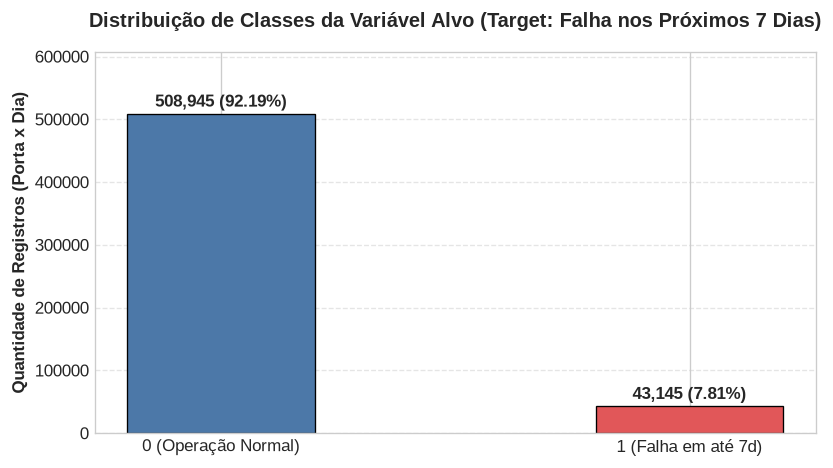

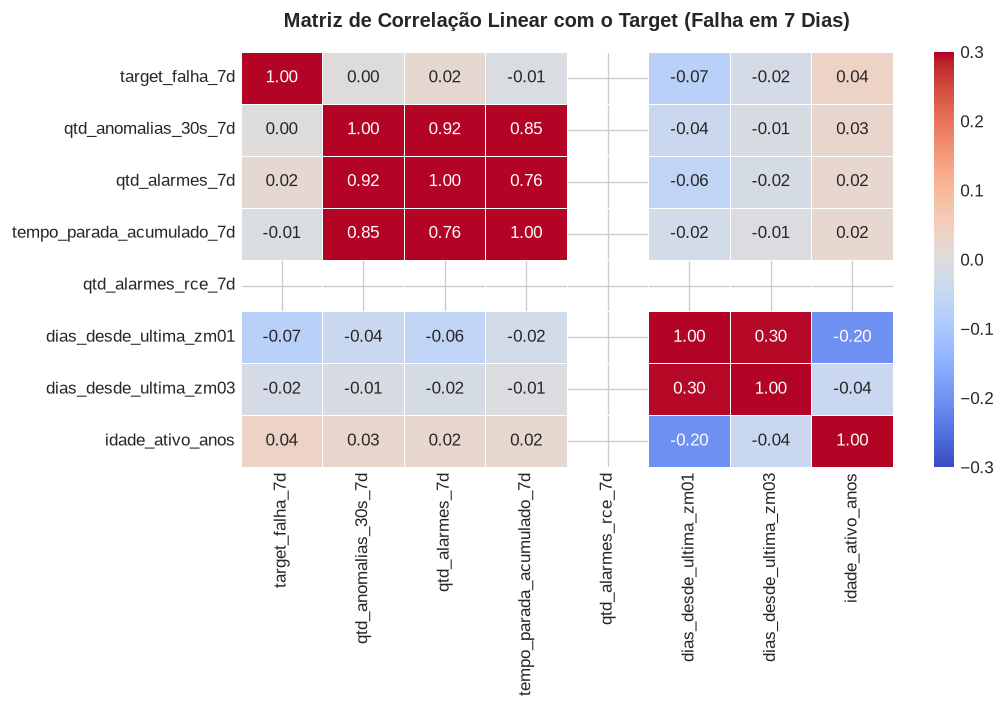

In [7]:
# Visualização 1: Distribuição das Classes do Target
fig, ax = plt.subplots(figsize=(7, 4))
contagens = df_mestra['target_falha_7d'].value_counts()
cores = ['#4c78a8', '#e15759']
rotulos = ['0 (Operação Normal)', '1 (Falha em até 7d)']

bars = ax.bar(rotulos, contagens.values, color=cores, width=0.4, edgecolor='black', linewidth=0.8)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 5000, f"{yval:,} ({(yval/total_amostras)*100:.2f}%)", ha='center', va='bottom', fontweight='bold')

ax.set_title('Distribuição de Classes da Variável Alvo (Target: Falha nos Próximos 7 Dias)', fontsize=12, fontweight='bold', pad=15)
ax.set_ylabel('Quantidade de Registros (Porta x Dia)', fontsize=10, fontweight='bold')
ax.set_ylim(0, total_amostras * 1.1)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Visualização 2: Correlação com o Target Preditivo
cols_correlacao = [
    'target_falha_7d', 'qtd_anomalias_30s_7d', 'qtd_alarmes_7d', 'tempo_parada_acumulado_7d',
    'qtd_alarmes_rce_7d', 'dias_desde_ultima_zm01', 'dias_desde_ultima_zm03', 'idade_ativo_anos'
]

matriz_corr = df_mestra[cols_correlacao].corr()

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-0.3, vmax=0.3, ax=ax, linewidths=0.5)
ax.set_title('Matriz de Correlação Linear com o Target (Falha em 7 Dias)', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()



## 8. Exportação da Tabela Mestra Bruta

Salvamos a Tabela Mestra Consolidada em formato CSV sem transformações, servindo como entrada direta para as próximas etapas de engenharia de features, encodings e treinamento dos modelos de Machine Learning.


In [8]:
# Seleção final de colunas organizadas
colunas_finais = [
    'id_ativo', 'estacao', 'plataforma', 'porta', 'data_ref',
    'dia_da_semana', 'dia_semana_num', 'flag_fim_de_semana', 'idade_ativo_anos',
    'qtd_alarmes_1d', 'qtd_alarmes_7d', 'qtd_alarmes_14d',
    'qtd_anomalias_30s_1d', 'qtd_anomalias_30s_7d', 'qtd_anomalias_30s_14d',
    'tempo_parada_acumulado_7d', 'max_tempo_normalizacao_7d',
    'qtd_alarmes_rce_7d', 'qtd_alarmes_fo_7d',
    'dias_desde_ultima_zm01', 'dias_desde_ultima_zm02', 'dias_desde_ultima_zm03',
    'target_falha_7d'
]

df_mestra_final = df_mestra[colunas_finais].copy()
output_path = "../../data/tabela_mestra_bruta.csv"

print(f"Exportando Tabela Mestra Bruta com {df_mestra_final.shape[0]:,} linhas e {df_mestra_final.shape[1]} colunas...")
df_mestra_final.to_csv(output_path, index=False, encoding='utf-8')
print(f"✅ Tabela Mestra exportada com sucesso em: {output_path}")



Exportando Tabela Mestra Bruta com 552,090 linhas e 23 colunas...
✅ Tabela Mestra exportada com sucesso em: ../../data/tabela_mestra_bruta.csv
